In [2]:
import numpy as np
import pandas as pd


In [7]:
data_dict = pd.read_csv('Data_Dictionary.csv',encoding='latin-1')
data_dict.head()


,Column no.,Variable Name,Description
0,1,SK_ID_CURR,Unique identifier for each client.
1,2,TARGET,"Whether the loan was repaid (1 for yes, 0 for ..."
2,3,NAME_CONTRACT_TYPE,"Type of loan contract (e.g., Cash loans, Revol..."
3,4,CODE_GENDER,Gender of the applicant.
4,5,FLAG_OWN_CAR,Whether the applicant owns a car (Yes/No).


In [6]:

data_loan = pd.read_csv('loan_data (1).csv')
data_loan.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [23]:
data_loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [8]:
print('Checking for null values and their percentages:')
null_counts = data_loan.isnull().sum()
null_percentages = (data_loan.isnull().sum() / len(data_loan)) * 100

null_info = pd.DataFrame({'Null Count': null_counts, 'Null Percentage': null_percentages})
null_info = null_info[null_info['Null Count'] > 0].sort_values(by='Null Percentage', ascending=False)

display(null_info)

Checking for null values and their percentages:


,Null Count,Null Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
...,...,...
EXT_SOURCE_2,660,0.214626
AMT_GOODS_PRICE,278,0.090403
AMT_ANNUITY,12,0.003902
CNT_FAM_MEMBERS,2,0.000650


In [13]:
default_percentage = (data_loan['TARGET'].value_counts(normalize=True) * 100).loc[1]
print(f"Percentage of default (TARGET = 1): {default_percentage:.2f}%")

Percentage of default (TARGET = 1): 8.07%


In [17]:
X = data_loan.drop('TARGET', axis=1)
y = data_loan['TARGET']

print("Original dataset shape:")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Target distribution:\n{y.value_counts()}")

# Identify categorical columns
categorical_cols = X.select_dtypes(include=['object']).columns

# Apply one-hot encoding
X_encoded = pd.get_dummies(X, columns=categorical_cols, dummy_na=False)

print("\nShape after one-hot encoding:")
print(f"X_encoded shape: {X_encoded.shape}")

# Impute missing values in X_encoded
# Filling NaN values with the mean of their respective columns
X_encoded = X_encoded.fillna(X_encoded.mean())

print("\nShape after imputation and one-hot encoding:")
print(f"X_encoded shape: {X_encoded.shape}")
print(f"Number of NaN values in X_encoded after imputation: {X_encoded.isnull().sum().sum()}")

Original dataset shape:
X shape: (307511, 121)
y shape: (307511,)
Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Shape after one-hot encoding:
X_encoded shape: (307511, 245)

Shape after imputation and one-hot encoding:
X_encoded shape: (307511, 245)
Number of NaN values in X_encoded after imputation: 0


In [18]:
from imblearn.over_sampling import SMOTE

smt = SMOTE(random_state=42)
X_balanced, y_balanced = smt.fit_resample(X_encoded, y)

print("Balanced dataset shape:")
print(f"X_balanced shape: {X_balanced.shape}")
print(f"y_balanced shape: {y_balanced.shape}")
print(f"Balanced target distribution:\n{y_balanced.value_counts()}")

Balanced dataset shape:
X_balanced shape: (565372, 245)
y_balanced shape: (565372,)
Balanced target distribution:
TARGET
1    282686
0    282686
Name: count, dtype: int64


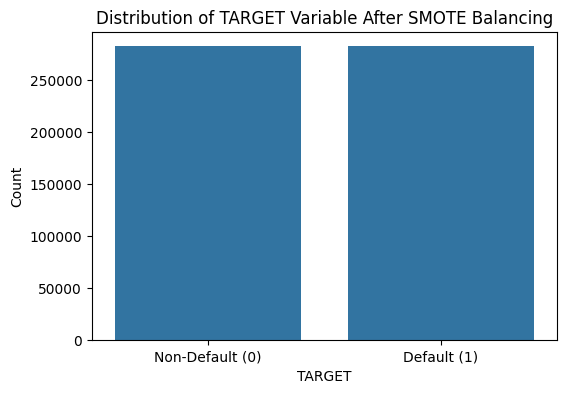

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(x=y_balanced)
plt.title('Distribution of TARGET Variable After SMOTE Balancing')
plt.xlabel('TARGET')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Non-Default (0)', 'Default (1)'])
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

# Split the balanced data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_balanced, y_balanced, test_size=0.2, random_state=42, stratify=y_balanced)

print("Shapes of the training and testing sets:")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

print("\nTarget distribution in training set:")
print(y_train.value_counts(normalize=True))

print("\nTarget distribution in testing set:")
print(y_test.value_counts(normalize=True))

Shapes of the training and testing sets:
X_train shape: (452297, 245)
X_test shape: (113075, 245)
y_train shape: (452297,)
y_test shape: (113075,)

Target distribution in training set:
TARGET
1    0.500001
0    0.499999
Name: proportion, dtype: float64

Target distribution in testing set:
TARGET
0    0.500004
1    0.499996
Name: proportion, dtype: float64


In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Define the model architecture
model = Sequential([
    Dense(256, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid') # Output layer for binary classification
])

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        62,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,193 (407.00 KB)

 Trainable params: 104,193 (407.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 44s 4ms/step - accuracy: 0.4997 - loss: 82.8721 - val_accuracy: 0.4990 - val_loss: 0.6932
Epoch 2/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.5001 - loss: 0.8279 - val_accuracy: 0.5010 - val_loss: 0.6931
Epoch 3/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.4999 - loss: 0.7725 - val_accuracy: 0.5010 - val_loss: 0.6932
Epoch 4/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.5000 - loss: 0.7465 - val_accuracy: 0.5010 - val_loss: 0.6932
Epoch 5/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.5012 - loss: 0.7466 - val_accuracy: 0.5010 - val_loss: 0.6932
Epoch 6/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.5002 - loss: 0.7214 - val_accuracy: 0.4990 - val_loss: 0.6932
Epoch 7/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.5009 - loss: 0.6943 - val_accuracy: 0.5010 - val_loss: 0.6931
Epoch 8/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy:

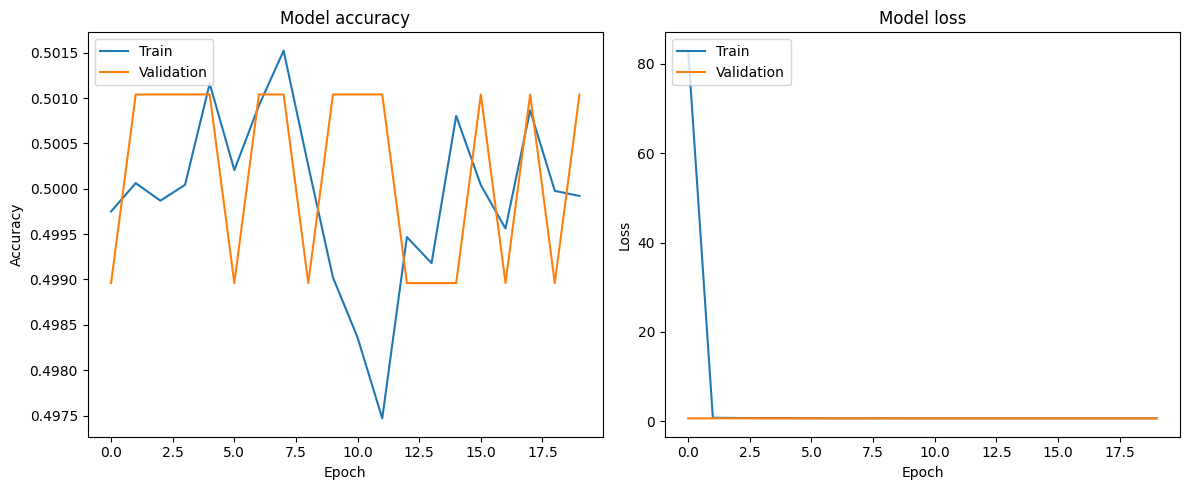

In [22]:
# Train the model
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2, verbose=1)

# Plot training history
plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

In [23]:
# Evaluate the model on the test set
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Test Loss: 0.6933
Test Accuracy: 0.5000


In [24]:
from sklearn.metrics import roc_curve, auc, confusion_matrix
import numpy as np

# Predict probabilities on the test set
y_pred_proba = model.predict(X_test).ravel()

# Convert probabilities to binary predictions based on a threshold (e.g., 0.5)
y_pred = (y_pred_proba > 0.5).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# Calculate Sensitivity (Recall) for the positive class (class 1)
# Sensitivity = True Positives / (True Positives + False Negatives)
true_positives = cm[1, 1]
false_negatives = cm[1, 0]
sensitivity = true_positives / (true_positives + false_negatives)
print(f"Sensitivity (Recall for positive class): {sensitivity:.4f}")

# Calculate AUC-ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)
print(f"AUC-ROC: {roc_auc:.4f}")

3534/3534 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step
Confusion Matrix:
[[    0 56538]
 [    0 56537]]
Sensitivity (Recall for positive class): 1.0000
AUC-ROC: 0.5000


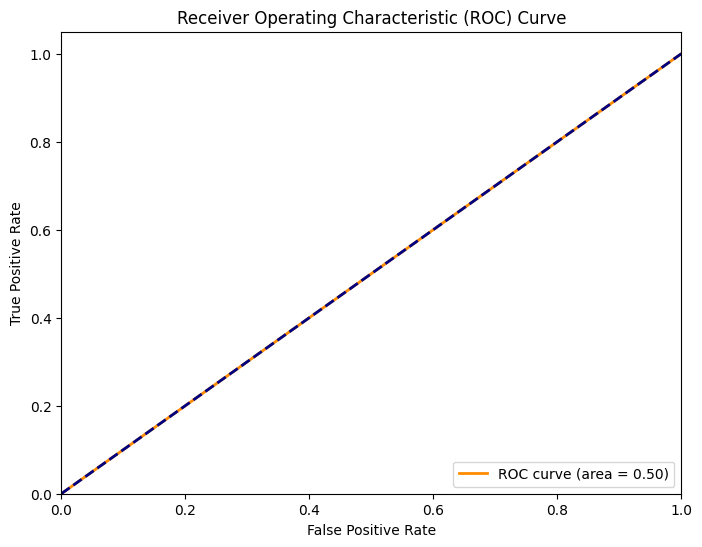

In [25]:
# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

In [ ]:
# To get a better model now using scaling

In [26]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Scale the balanced features
X_scaled = scaler.fit_transform(X_balanced)

# Convert the scaled array back to a DataFrame with original column names
X_scaled = pd.DataFrame(X_scaled, columns=X_balanced.columns)

print("Shape of scaled data:", X_scaled.shape)
print("First 5 rows of scaled data (example):")
print(X_scaled.head())

Shape of scaled data: (565372, 245)
First 5 rows of scaled data (example):
   SK_ID_CURR  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0   -1.736255     -0.521079          0.092819   -0.459006    -0.154674   
1   -1.736245     -0.521079          0.266264    1.886433     0.672310   
2   -1.736235     -0.521079         -0.254072   -1.177251    -1.504445   
3   -1.736216     -0.521079         -0.080627   -0.707366     0.220243   
4   -1.736206     -0.521079         -0.115316   -0.177622    -0.367849   

   AMT_GOODS_PRICE  REGION_POPULATION_RELATIVE  DAYS_BIRTH  DAYS_EMPLOYED  \
0        -0.478403                   -0.103370    1.452815      -0.413667   
1         1.780012                   -1.354240   -0.308641      -0.417835   
2        -1.105015                   -0.822170   -0.858735      -0.410551   
3        -0.635056                   -0.987176   -0.848847      -0.431837   
4        -0.008443                    0.705023   -1.072406      -0.431829   

   DAYS_REGISTRAT

In [27]:
# Split the scaled balanced data into training and testing sets
X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled = train_test_split(X_scaled, y_balanced, test_size=0.2, random_state=42, stratify=y_balanced)

print("Shapes of the scaled training and testing sets:")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape: {X_test_scaled.shape}")
print(f"y_train_scaled shape: {y_train_scaled.shape}")
print(f"y_test_scaled shape: {y_test_scaled.shape}")

print("\nTarget distribution in scaled training set:")
print(y_train_scaled.value_counts(normalize=True))

print("\nTarget distribution in scaled testing set:")
print(y_test_scaled.value_counts(normalize=True))

Shapes of the scaled training and testing sets:
X_train_scaled shape: (452297, 245)
X_test_scaled shape: (113075, 245)
y_train_scaled shape: (452297,)
y_test_scaled shape: (113075,)

Target distribution in scaled training set:
TARGET
1    0.500001
0    0.499999
Name: proportion, dtype: float64

Target distribution in scaled testing set:
TARGET
0    0.500004
1    0.499996
Name: proportion, dtype: float64


In [28]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Define the model architecture using the scaled training data shape
model_scaled = Sequential([
    Dense(256, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid') # Output layer for binary classification
])

# Compile the model
model_scaled.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model_scaled.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │        62,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,193 (407.00 KB)

 Trainable params: 104,193 (407.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 46s 4ms/step - accuracy: 0.9497 - loss: 0.1594 - val_accuracy: 0.9547 - val_loss: 0.1426
Epoch 2/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 0.9540 - loss: 0.1449 - val_accuracy: 0.9554 - val_loss: 0.1407
Epoch 3/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 0.9544 - loss: 0.1434 - val_accuracy: 0.9555 - val_loss: 0.1391
Epoch 4/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 0.9545 - loss: 0.1426 - val_accuracy: 0.9556 - val_loss: 0.1405
Epoch 5/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.9547 - loss: 0.1422 - val_accuracy: 0.9560 - val_loss: 0.1396
Epoch 6/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.9547 - loss: 0.1422 - val_accuracy: 0.9555 - val_loss: 0.1429
Epoch 7/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.9548 - loss: 0.1422 - val_accuracy: 0.9558 - val_loss: 0.1408
Epoch 8/20
11308/11308 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 

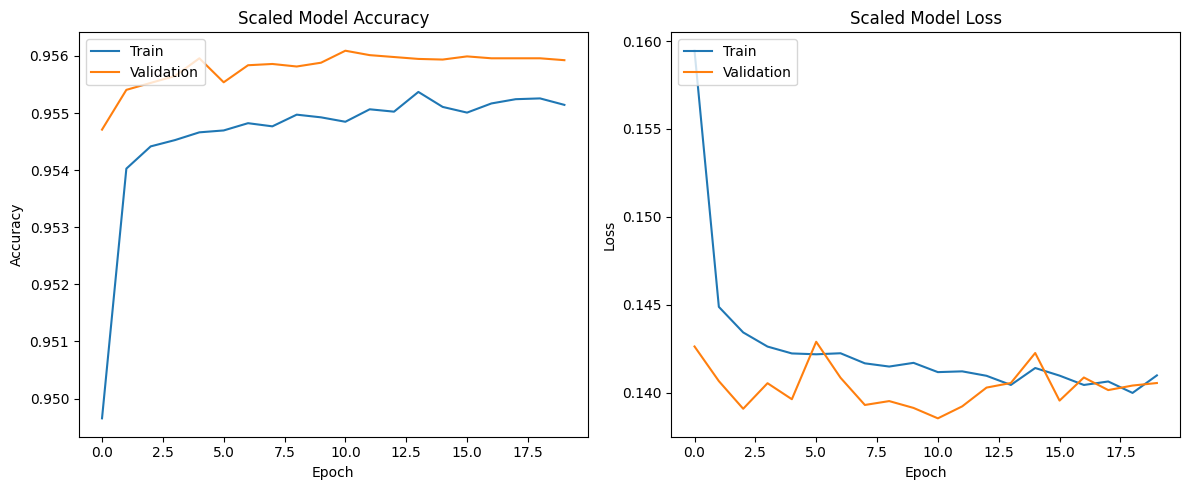

In [29]:
# Train the scaled model
history_scaled = model_scaled.fit(X_train_scaled, y_train_scaled, epochs=20, batch_size=32, validation_split=0.2, verbose=1)

# Plot training history
plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(history_scaled.history['accuracy'])
plt.plot(history_scaled.history['val_accuracy'])
plt.title('Scaled Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history_scaled.history['loss'])
plt.plot(history_scaled.history['val_loss'])
plt.title('Scaled Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

In [30]:
# Evaluate the scaled model on the scaled test set
loss_scaled, accuracy_scaled = model_scaled.evaluate(X_test_scaled, y_test_scaled, verbose=0)
print(f"Scaled Test Loss: {loss_scaled:.4f}")
print(f"Scaled Test Accuracy: {accuracy_scaled:.4f}")

Scaled Test Loss: 0.1737
Scaled Test Accuracy: 0.9558


In [31]:
from sklearn.metrics import roc_curve, auc, confusion_matrix
import numpy as np

# Predict probabilities on the scaled test set
y_pred_proba_scaled = model_scaled.predict(X_test_scaled).ravel()

# Convert probabilities to binary predictions based on a threshold (e.g., 0.5)
y_pred_scaled = (y_pred_proba_scaled > 0.5).astype(int)

# Calculate confusion matrix for scaled model
cm_scaled = confusion_matrix(y_test_scaled, y_pred_scaled)
print("Confusion Matrix (Scaled Model):")
print(cm_scaled)

# Calculate Sensitivity (Recall) for the positive class (class 1) for scaled model
# Sensitivity = True Positives / (True Positives + False Negatives)
true_positives_scaled = cm_scaled[1, 1]
false_negatives_scaled = cm_scaled[1, 0]
sensitivity_scaled = true_positives_scaled / (true_positives_scaled + false_negatives_scaled)
print(f"Sensitivity (Recall for positive class - Scaled Model): {sensitivity_scaled:.4f}")

# Calculate AUC-ROC for scaled model
fpr_scaled, tpr_scaled, thresholds_scaled = roc_curve(y_test_scaled, y_pred_proba_scaled)
roc_auc_scaled = auc(fpr_scaled, tpr_scaled)
print(f"AUC-ROC (Scaled Model): {roc_auc_scaled:.4f}")

3534/3534 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step
Confusion Matrix (Scaled Model):
[[56530     8]
 [ 4995 51542]]
Sensitivity (Recall for positive class - Scaled Model): 0.9117
AUC-ROC (Scaled Model): 0.9774


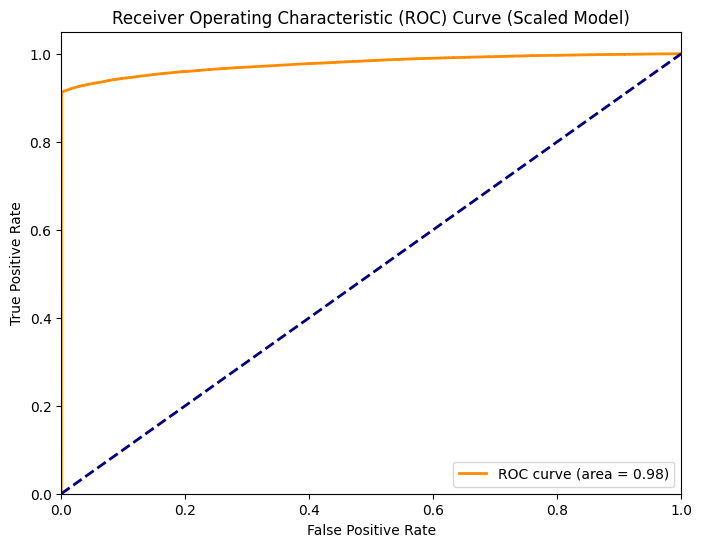

In [32]:
# Plot ROC curve for scaled model
plt.figure(figsize=(8, 6))
plt.plot(fpr_scaled, tpr_scaled, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_scaled:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve (Scaled Model)')
plt.legend(loc='lower right')
plt.show()